# Notebook 57 — VAE image experiment and latent-space analysis

The previous notebooks developed [deterministic autoencoders](./55_autoencoders_and_latent_spaces.ipynb) and the [VAE objective](./56_variational_autoencoders_and_elbo.ipynb) on a small synthetic dataset. We now compare both models on resized CIFAR-10 images while keeping their convolutional architectures and latent widths as similar as possible.

The central comparison is not only reconstruction loss. We will also inspect image sharpness, class structure in latent space, interpolation, regular latent grids, and samples drawn from the same standard-normal distribution.

## Learning goals

- build comparable convolutional AE and VAE models;
- compare reconstruction quality with latent-space regularity;
- visualize two-dimensional latent representations by class;
- distinguish interpolation, reconstruction, and generation;
- compare arbitrary AE prior samples with meaningful VAE prior samples;
- interpret reconstruction and KL curves;
- optionally examine the effect of the KL weight $\beta$.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import CIFAR10

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from cs231n_practice.generative import (
    gaussian_kl_divergence,
    reparameterize,
    vae_loss,
)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("device:", DEVICE)

device: mps


## 1. Balanced CIFAR-10 subsets

We use 6,000 training, 1,000 validation, and 1,000 test images, balanced across the ten classes. Images are average-pooled from $32\times32$ to $16\times16$.

Unlike classification experiments, we do **not** standardize channels using a mean and standard deviation. Bernoulli reconstruction targets must remain in $[0,1]$, and sigmoid decoder outputs have that same interpretation.

In [2]:
DATA_DIR = PROJECT_ROOT / "data"
CLASS_NAMES = ("airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")

train_dataset = CIFAR10(root=DATA_DIR, train=True, download=True)
test_dataset = CIFAR10(root=DATA_DIR, train=False, download=True)
train_targets = np.asarray(train_dataset.targets, dtype=np.int64)
test_targets = np.asarray(test_dataset.targets, dtype=np.int64)
split_generator = np.random.default_rng(SEED)

training_parts, validation_parts = [], []
for class_index in range(10):
    indices = split_generator.permutation(np.flatnonzero(train_targets == class_index))[:700]
    training_parts.append(indices[:600])
    validation_parts.append(indices[600:700])
training_indices = split_generator.permutation(np.concatenate(training_parts))
validation_indices = split_generator.permutation(np.concatenate(validation_parts))

test_parts = []
for class_index in range(10):
    indices = split_generator.permutation(np.flatnonzero(test_targets == class_index))[:100]
    test_parts.append(indices)
test_indices = split_generator.permutation(np.concatenate(test_parts))


def downsample_to_nchw(images):
    images = images.astype(np.float32) / 255.0
    images = images.reshape(-1, 16, 2, 16, 2, 3).mean(axis=(2, 4))
    return images.transpose(0, 3, 1, 2)


X_train = downsample_to_nchw(train_dataset.data[training_indices])
X_validation = downsample_to_nchw(train_dataset.data[validation_indices])
X_test = downsample_to_nchw(test_dataset.data[test_indices])
y_train = train_targets[training_indices]
y_validation = train_targets[validation_indices]
y_test = test_targets[test_indices]

assert X_train.shape == (6000, 3, 16, 16)
assert np.array_equal(np.bincount(y_train), np.full(10, 600))
assert X_train.min() >= 0.0 and X_train.max() <= 1.0
print("train / validation / test:", len(X_train), len(X_validation), len(X_test))

train / validation / test: 6000 1000 1000


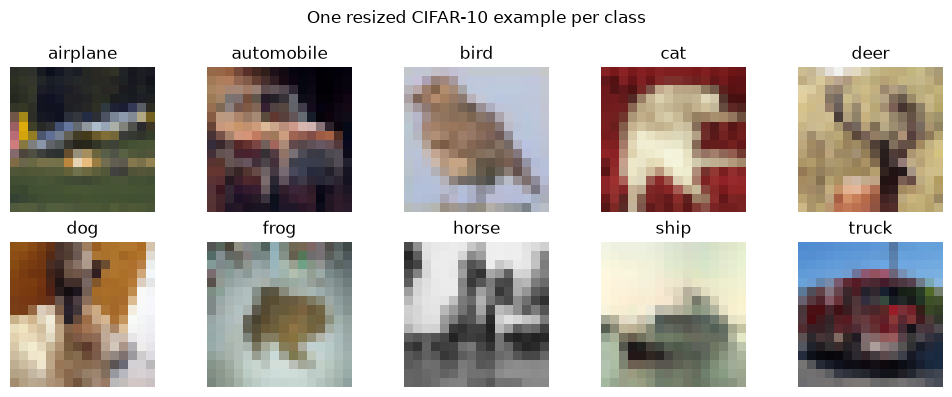

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for label, axis in enumerate(axes.flat):
    index = int(np.flatnonzero(y_train == label)[0])
    axis.imshow(X_train[index].transpose(1, 2, 0))
    axis.set_title(CLASS_NAMES[label])
    axis.axis("off")
plt.suptitle("One resized CIFAR-10 example per class")
plt.tight_layout()
plt.show()

## 2. Comparable convolutional models

Both encoders reduce $(N,3,16,16)$ images to a hidden vector through two stride-two convolutions:

```text
(N, 3, 16, 16) -> (N, 16, 8, 8) -> (N, 32, 4, 4) -> (N, 512)
```

The deterministic AE produces one latent vector. The VAE produces the mean and log-variance of a distribution. Their decoders have the same structure and return raw logits.

A two-dimensional latent space is intentionally restrictive for color images. It makes visualization possible, but we should expect softer reconstructions than a model with a larger latent width.

### Exercise 1 — Complete the convolutional models

In [4]:
class ConvolutionalDecoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.projection = nn.Linear(latent_dim, 32 * 4 * 4)
        self.network = nn.Sequential(
            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 3, kernel_size=4, stride=2, padding=1),
        )

    def forward(self, latent_codes):
        hidden = F.relu(self.projection(latent_codes))
        hidden = hidden.reshape(-1, 32, 4, 4)
        return self.network(hidden)


class ConvolutionalAutoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder_features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
        )
        self.encoder_output = nn.Linear(32 * 4 * 4, latent_dim)
        self.decoder = ConvolutionalDecoder(latent_dim)

    def encode(self, images):
        # calculate features, flatten all non-batch axes, and return latent codes.
        features = self.encoder_features(images)
        flattened = features.reshape(-1, 32 * 4 * 4)
        return self.encoder_output(flattened)

    def decode(self, latent_codes):
        return self.decoder(latent_codes)

    def forward(self, images):
        return self.decode(self.encode(images))


class ConvolutionalVAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder_features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
        )
        self.mean_output = nn.Linear(32 * 4 * 4, latent_dim)
        self.log_variance_output = nn.Linear(32 * 4 * 4, latent_dim)
        self.decoder = ConvolutionalDecoder(latent_dim)

    def encode(self, images):
        # return the mean and log-variance from the same flattened features.
        features = self.encoder_features(images)
        flattened = features.reshape(-1, 32 * 4 * 4)
        return self.mean_output(flattened), self.log_variance_output(flattened)

    def decode(self, latent_codes):
        return self.decoder(latent_codes)

    def forward(self, images):
        # encode, reparameterize, decode, and return logits, mean, log-variance, and z.
        mean, log_variance = self.encode(images)
        z = self.reparameterize(mean, log_variance)
        logits = self.decode(z)
        return logits, mean, log_variance, z

    def reparameterize(self, mean, log_variance):
        std = torch.exp(0.5 * log_variance)
        eps = torch.randn_like(std)
        return mean + eps * std


toy_images = torch.from_numpy(X_train[:5]).to(DEVICE)
ae_shape_model = ConvolutionalAutoencoder().to(DEVICE)
vae_shape_model = ConvolutionalVAE().to(DEVICE)
assert ae_shape_model(toy_images).shape == toy_images.shape
vae_logits, vae_mean, vae_log_variance, vae_codes = vae_shape_model(toy_images)
assert vae_logits.shape == toy_images.shape
assert vae_mean.shape == vae_log_variance.shape == vae_codes.shape == (5, 2)

## 3. Parameter counts and comparable objectives

The models are not exactly identical because the VAE needs a second encoder output head, but most of their capacity is shared. Both reconstruction losses sum over channels and pixels within each image and then average across the batch. The VAE additionally pays KL divergence per image.

### Exercise 2 — Implement the AE objective and compare capacity

In [5]:
def parameter_count(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


def autoencoder_loss(reconstruction_logits, targets):
    # sum pixel/channel BCE inside each image, then average over the batch.
    batch_size = reconstruction_logits.shape[0]
    return F.binary_cross_entropy_with_logits(reconstruction_logits, targets, reduction="sum") / batch_size


print("AE parameters:", parameter_count(ae_shape_model))
print("VAE parameters:", parameter_count(vae_shape_model))
toy_ae_loss = autoencoder_loss(ae_shape_model(toy_images), toy_images)
assert toy_ae_loss.ndim == 0 and toy_ae_loss > 0

AE parameters: 20549
VAE parameters: 21575


## 4. Train the baseline and VAE

We use the same optimizer, learning rate, batch size, number of epochs, and shuffled batches. The [AE](./55_autoencoders_and_latent_spaces.ipynb) minimizes reconstruction alone. The [VAE](./56_variational_autoencoders_and_elbo.ipynb) minimizes reconstruction plus KL divergence.

Because the latent sample is stochastic, exact trajectories will differ even with similar initialization. This is a controlled comparison, not a claim that the architectures are perfectly matched.

### Exercise 3 — Complete the shared training loop

In [6]:
train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train)),
    batch_size=128,
    shuffle=True,
)


def train_reconstruction_model(model, loader, epochs=30, learning_rate=1e-3, beta=None):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    names = ("reconstruction",) if beta is None else ("total", "reconstruction", "kl")
    history = {name: [] for name in names}

    for epoch in range(epochs):
        totals = {name: 0.0 for name in names}
        number_images = 0
        model.train()
        for (images,) in loader:
            images = images.to(DEVICE)
            optimizer.zero_grad()

            if beta is None:
                # forward through the AE and calculate reconstruction loss.
                reconstruction_loss = autoencoder_loss(model(images), images)
                loss = reconstruction_loss
                batch_losses = {"reconstruction": reconstruction_loss}
            else:
                # forward through the VAE and calculate total, reconstruction, and KL losses.
                reconstruction_logits, mean, log_variance, z = model(images)
                total_loss, reconstruction_loss, kl_loss = vae_loss(
                    reconstruction_logits,
                    images,
                    mean,
                    log_variance,
                    beta=beta
                )
                loss = total_loss
                batch_losses = {"total": total_loss, "reconstruction": reconstruction_loss, "kl": kl_loss}

            # backpropagate and update the selected model.
            loss.backward()
            optimizer.step()
            batch_count = images.shape[0]
            for name, value in batch_losses.items():
                totals[name] += value.item() * batch_count
            number_images += batch_count

        for name in names:
            history[name].append(totals[name] / number_images)
        if epoch == 0 or (epoch + 1) % 5 == 0:
            summary = ", ".join(f"{name}={history[name][-1]:.2f}" for name in names)
            print(f"epoch {epoch + 1:2d}: {summary}")

    return history


torch.manual_seed(SEED)
autoencoder = ConvolutionalAutoencoder(latent_dim=2).to(DEVICE)
ae_history = train_reconstruction_model(autoencoder, train_loader)

torch.manual_seed(SEED)
vae = ConvolutionalVAE(latent_dim=2).to(DEVICE)
vae_history = train_reconstruction_model(vae, train_loader, beta=1.0)

assert ae_history["reconstruction"][-1] < ae_history["reconstruction"][0]
assert vae_history["total"][-1] < vae_history["total"][0]

epoch  1: reconstruction=527.07
epoch  5: reconstruction=489.19
epoch 10: reconstruction=487.94
epoch 15: reconstruction=487.65
epoch 20: reconstruction=487.50
epoch 25: reconstruction=487.40
epoch 30: reconstruction=487.38
epoch  1: total=530.04, reconstruction=529.94, kl=0.10
epoch  5: total=498.71, reconstruction=494.22, kl=4.49
epoch 10: total=493.46, reconstruction=489.43, kl=4.03
epoch 15: total=492.73, reconstruction=488.86, kl=3.88
epoch 20: total=492.39, reconstruction=488.67, kl=3.73
epoch 25: total=492.13, reconstruction=488.37, kl=3.76
epoch 30: total=492.03, reconstruction=488.26, kl=3.76


## 5. Reconstruction quality and sharpness

For stable VAE reconstruction, we decode the posterior mean rather than a random posterior sample. A simple sharpness proxy is average absolute change between neighboring pixels. It does not measure semantic quality, but it helps quantify visibly smoother outputs.

### Exercise 4 — Reconstruct and calculate the sharpness proxy

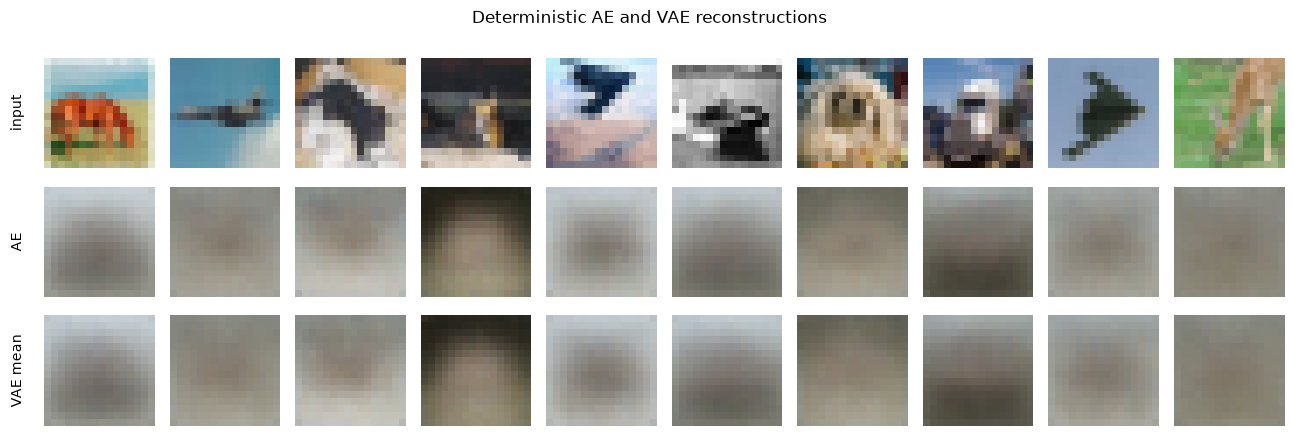

input    sharpness: 0.1594
AE       sharpness: 0.0342
VAE mean sharpness: 0.0349


In [7]:
@torch.no_grad()
def reconstruct_models(autoencoder, vae, images):
    autoencoder.eval()
    vae.eval()
    images = images.to(DEVICE)
    # decode AE codes and VAE posterior means; apply sigmoid to both logits.
    ae_codes = autoencoder.encode(images)
    ae_reconstructions = torch.sigmoid(autoencoder.decode(ae_codes))

    vae_mean, _ = vae.encode(images)
    vae_reconstructions = torch.sigmoid(vae.decode(vae_mean))

    return ae_reconstructions, vae_reconstructions


def spatial_sharpness(images):
    # average absolute horizontal and vertical neighbor differences.
    absolute_vertical_differences = torch.abs(images[:, :, 1:, :] - images[:, :, :-1, :])
    absolute_horizontal_differences = torch.abs(images[:, :, :, 1:] - images[:, :, :, :-1])
    return torch.mean(absolute_vertical_differences) + torch.mean(absolute_horizontal_differences)


comparison_images = torch.from_numpy(X_test[:10])
ae_reconstructions, vae_reconstructions = reconstruct_models(autoencoder, vae, comparison_images)
rows = (comparison_images, ae_reconstructions.cpu(), vae_reconstructions.cpu())
labels = ("input", "AE", "VAE mean")
fig, axes = plt.subplots(3, 10, figsize=(13, 4.5))
for row, (images, label) in enumerate(zip(rows, labels)):
    for column, image in enumerate(images):
        axes[row, column].imshow(image.permute(1, 2, 0).clamp(0, 1))
        axes[row, column].axis("off")
    axes[row, 0].text(-0.18, 0.5, label, transform=axes[row, 0].transAxes, rotation=90, va="center", ha="right")
plt.suptitle("Deterministic AE and VAE reconstructions")
plt.tight_layout()
plt.show()

for name, images in zip(labels, rows):
    print(f"{name:8s} sharpness: {spatial_sharpness(images):.4f}")

## 6. Latent means colored by class

CIFAR labels are used only for coloring; neither model receives them during training. For the AE we plot deterministic codes. For the VAE we plot posterior means. Class overlap is expected because the objective optimizes reconstruction and prior matching, not classification.

### Exercise 5 — Encode the validation set

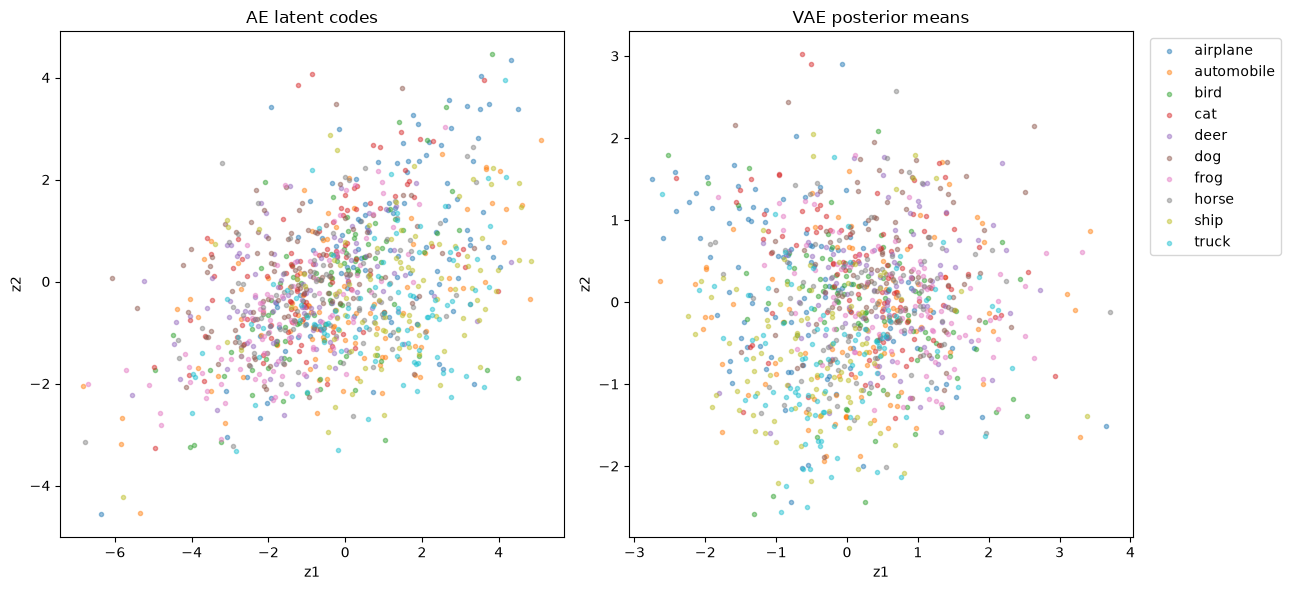

In [8]:
@torch.no_grad()
def encode_latent_means(model, images, variational=False, batch_size=256):
    model.eval()
    encoded = []
    for start in range(0, len(images), batch_size):
        batch = torch.from_numpy(images[start:start + batch_size]).to(DEVICE)
        # append AE codes or the first VAE encoder output.
        if variational:
            mean, log_variance = model.encode(batch)
            encoded.append(mean)
        else:
            codes = model.encode(batch)
            encoded.append(codes)
    return torch.cat(encoded).cpu()


ae_validation_codes = encode_latent_means(autoencoder, X_validation)
vae_validation_means = encode_latent_means(vae, X_validation, variational=True)
assert ae_validation_codes.shape == vae_validation_means.shape == (1000, 2)

fig, axes = plt.subplots(1, 2, figsize=(13,6))
for label, name in enumerate(CLASS_NAMES):
    selected = y_validation == label
    axes[0].scatter(ae_validation_codes[selected, 0], ae_validation_codes[selected, 1], s=9, alpha=0.45, label=name)
    axes[1].scatter(vae_validation_means[selected, 0], vae_validation_means[selected, 1], s=9, alpha=0.45, label=name)
axes[0].set(title="AE latent codes", xlabel="z1", ylabel="z2")
axes[1].set(title="VAE posterior means", xlabel="z1", ylabel="z2")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

2dim did what it could, below is 32dim experiment

## 7. Repeat the comparison with a wider latent space

The two-dimensional bottleneck is useful for direct visualization but is extremely restrictive for CIFAR-10. We now repeat the controlled comparison with latent width 32 while keeping the dataset, convolutional channels, optimizer, and training schedule unchanged. This isolates the effect of latent capacity.

The original two-dimensional models remain useful for the regular grid in the next section. The wider models will be used for the later reconstruction, interpolation, prior-sampling, and training-curve comparisons.

In [9]:
torch.manual_seed(SEED)
autoencoder_32 = ConvolutionalAutoencoder(latent_dim=32).to(DEVICE)
ae_history_32 = train_reconstruction_model(autoencoder_32, train_loader)

torch.manual_seed(SEED)
vae_32 = ConvolutionalVAE(latent_dim=32).to(DEVICE)
vae_history_32 = train_reconstruction_model(vae_32, train_loader, beta=1.0)

assert ae_history_32["reconstruction"][-1] < ae_history_32["reconstruction"][0]
assert vae_history_32["total"][-1] < vae_history_32["total"][0]
print("AE 2D / 32D final reconstruction:", ae_history["reconstruction"][-1], ae_history_32["reconstruction"][-1])
print("VAE 2D / 32D final reconstruction:", vae_history["reconstruction"][-1], vae_history_32["reconstruction"][-1])

epoch  1: reconstruction=525.98
epoch  5: reconstruction=468.52
epoch 10: reconstruction=460.72
epoch 15: reconstruction=456.94
epoch 20: reconstruction=455.03
epoch 25: reconstruction=450.98
epoch 30: reconstruction=449.51
epoch  1: total=529.77, reconstruction=529.28, kl=0.49
epoch  5: total=492.10, reconstruction=482.95, kl=9.15
epoch 10: total=484.27, reconstruction=473.86, kl=10.40
epoch 15: total=481.17, reconstruction=470.13, kl=11.04
epoch 20: total=479.60, reconstruction=467.74, kl=11.86
epoch 25: total=477.66, reconstruction=464.88, kl=12.78
epoch 30: total=476.84, reconstruction=463.78, kl=13.06
AE 2D / 32D final reconstruction: 487.3832438964844 449.51458618164065
VAE 2D / 32D final reconstruction: 488.263341796875 463.780169921875


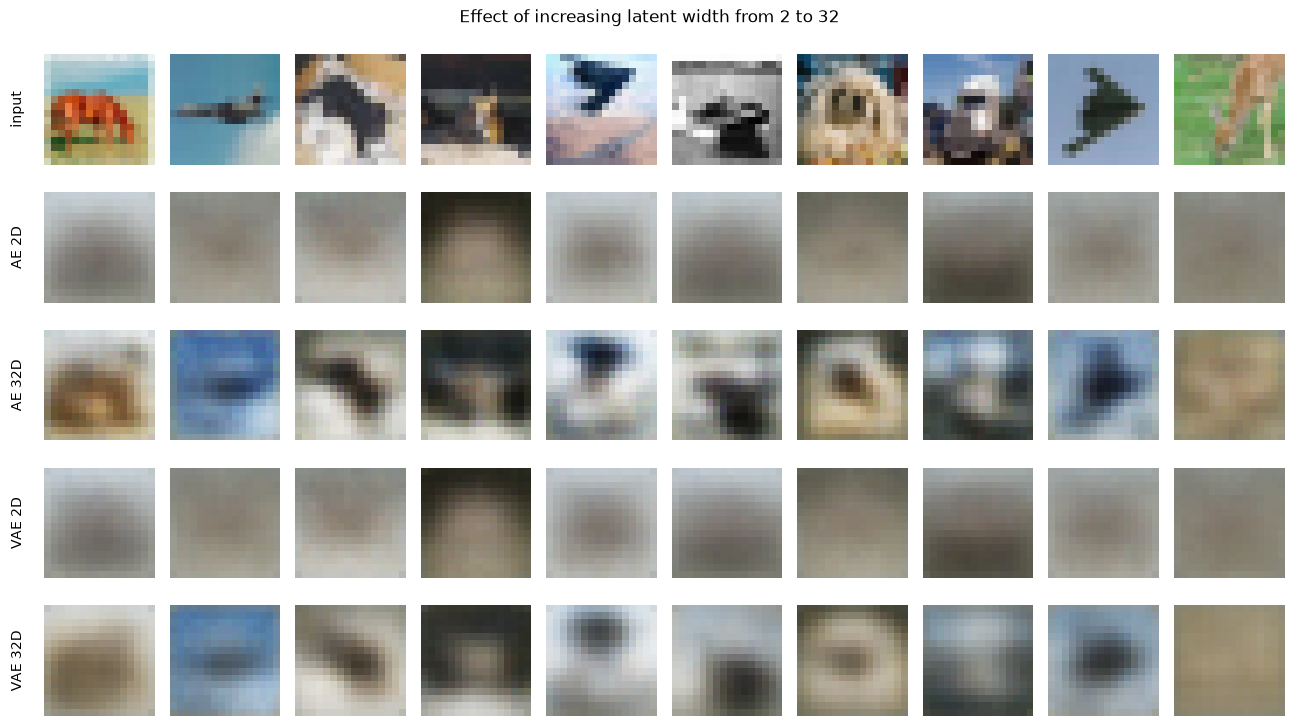

input    sharpness: 0.1594
AE 2D    sharpness: 0.0342
AE 32D   sharpness: 0.1002
VAE 2D   sharpness: 0.0349
VAE 32D  sharpness: 0.0641


In [10]:
ae_reconstructions_32, vae_reconstructions_32 = reconstruct_models(
    autoencoder_32, vae_32, comparison_images
)
comparison_rows = (
    comparison_images, ae_reconstructions.cpu(), ae_reconstructions_32.cpu(),
    vae_reconstructions.cpu(), vae_reconstructions_32.cpu(),
)
comparison_labels = ("input", "AE 2D", "AE 32D", "VAE 2D", "VAE 32D")
fig, axes = plt.subplots(5, 10, figsize=(13, 7.5))
for row, (images, label) in enumerate(zip(comparison_rows, comparison_labels)):
    for column, image in enumerate(images):
        axes[row, column].imshow(image.permute(1, 2, 0).clamp(0, 1))
        axes[row, column].axis("off")
    axes[row, 0].text(-0.18, 0.5, label, transform=axes[row, 0].transAxes, rotation=90, va="center", ha="right")
plt.suptitle("Effect of increasing latent width from 2 to 32")
plt.tight_layout()
plt.show()

for name, images in zip(comparison_labels, comparison_rows):
    print(f"{name:8s} sharpness: {spatial_sharpness(images):.4f}")

## 8. Decode regular two-dimensional latent grids

A regular grid asks what the decoder produces between and around encoded examples. This visualization specifically requires the original two-dimensional models. We use each model's observed validation range so both grids cover their occupied regions. Smooth changes are useful, but they do not by themselves prove that arbitrary prior samples are reliable.

### Exercise 6 — Construct and decode a two-dimensional grid

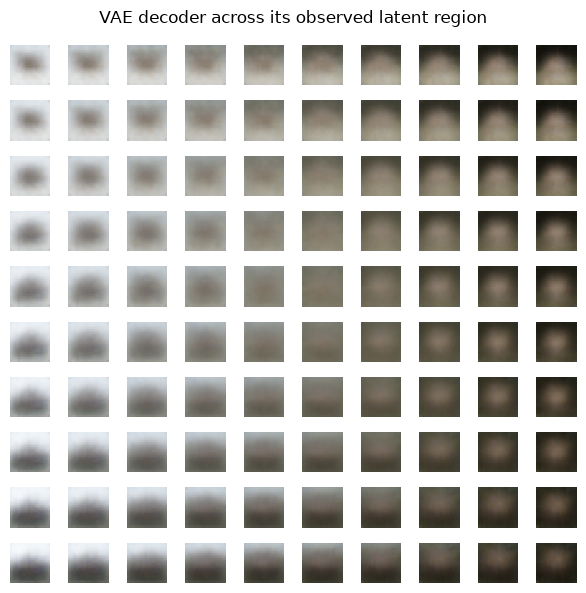

In [11]:
@torch.no_grad()
def decode_observed_grid(model, observed_codes, grid_size=10):
    if observed_codes.ndim != 2 or observed_codes.shape[1] != 2:
        raise ValueError("observed_codes must have shape (N, 2)")

    # Ignore the most extreme two percent at each end so a few outliers do
    # not make the useful central part of the grid unnecessarily sparse.
    codes = observed_codes.detach().cpu().to(torch.float32)
    lower = torch.quantile(codes, 0.02, dim=0)
    upper = torch.quantile(codes, 0.98, dim=0)
    first_axis = torch.linspace(lower[0], upper[0], grid_size)
    second_axis = torch.linspace(upper[1], lower[1], grid_size)

    # Each displayed column changes z1, while each displayed row changes z2.
    # Flattening the two coordinate grids and stacking along dim=1 creates
    # one latent coordinate pair per row: (grid_size ** 2, 2).
    grid_second, grid_first = torch.meshgrid(
        second_axis, first_axis, indexing="ij"
    )
    grid_codes = torch.stack(
        (grid_first.reshape(-1), grid_second.reshape(-1)), dim=1
    )

    grid_images = model.decode(grid_codes.to(DEVICE))
    return torch.sigmoid(grid_images).cpu()


ae_grid = decode_observed_grid(autoencoder, ae_validation_codes)
vae_grid = decode_observed_grid(vae, vae_validation_means)
assert ae_grid.shape == vae_grid.shape == (100, 3, 16, 16)

fig, axes = plt.subplots(10, 10, figsize=(6, 6))
for axis, image in zip(axes.flat, vae_grid):
    axis.imshow(image.permute(1, 2, 0).clamp(0, 1))
    axis.axis("off")
plt.suptitle("VAE decoder across its observed latent region")
plt.tight_layout()
plt.show()

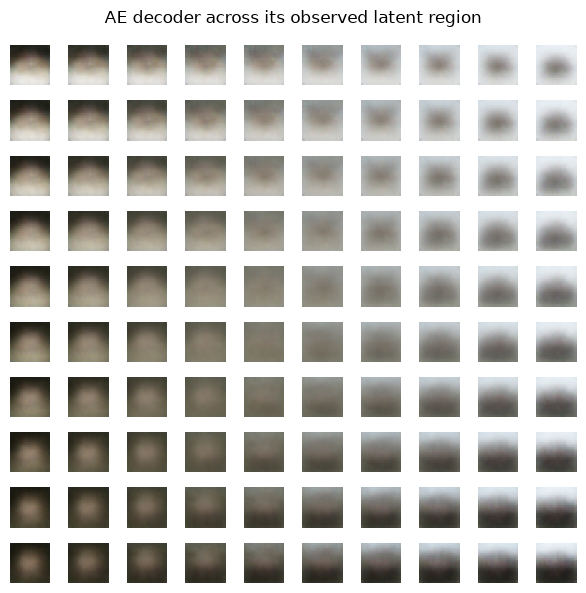

In [12]:
fig, axes = plt.subplots(10, 10, figsize=(6, 6))
for axis, image in zip(axes.flat, ae_grid):
    axis.imshow(image.permute(1, 2, 0).clamp(0, 1))
    axis.axis("off")
plt.suptitle("AE decoder across its observed latent region")
plt.tight_layout()
plt.show()

## 9. Interpolate between examples

Interpolation begins with two real images, encodes both endpoints, and decodes intermediate latent values. It is therefore different from unconditional generation, even though most intermediate codes do not correspond to an observed image.

For the VAE we interpolate between posterior means to remove sampling noise from the comparison. We use the wider 32-dimensional models here; the interpolation is still a one-dimensional path between two endpoints inside that larger space.

### Exercise 7 — Interpolate both latent spaces

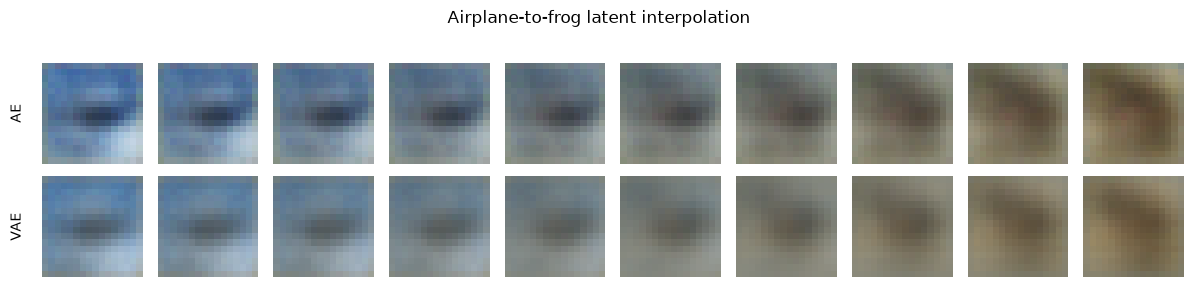

In [13]:
@torch.no_grad()
def interpolate_images(model, first_image, second_image, steps=10, variational=False):
    model.eval()
    endpoints = torch.stack((first_image, second_image)).to(DEVICE)
    # Encode both images together. For the VAE, use the two posterior means
    # so fresh sampling noise does not change the interpolation endpoints.
    if variational:
        endpoint_latents, _ = model.encode(endpoints)
    else:
        endpoint_latents = model.encode(endpoints)

    # alpha has shape (steps, 1), so broadcasting combines it with each
    # endpoint vector of shape (latent_dim,) to produce (steps, latent_dim).
    alpha = torch.linspace(0.0, 1.0, steps, device=DEVICE).unsqueeze(1)
    interpolated_latents = (
        (1.0 - alpha) * endpoint_latents[0]
        + alpha * endpoint_latents[1]
    )
    assert interpolated_latents.shape == (steps, model.latent_dim)

    decoded_images = model.decode(interpolated_latents)
    return torch.sigmoid(decoded_images).cpu()


first = torch.from_numpy(X_test[np.flatnonzero(y_test == 0)[0]])
second = torch.from_numpy(X_test[np.flatnonzero(y_test == 6)[0]])
ae_interpolation = interpolate_images(autoencoder_32, first, second)
vae_interpolation = interpolate_images(vae_32, first, second, variational=True)

fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for row, (images, label) in enumerate(((ae_interpolation, "AE"), (vae_interpolation, "VAE"))):
    for column, image in enumerate(images):
        axes[row, column].imshow(image.permute(1, 2, 0).clamp(0, 1))
        axes[row, column].axis("off")
    axes[row, 0].text(-0.18, 0.5, label, transform=axes[row, 0].transAxes, rotation=90, va="center", ha="right")
plt.suptitle("Airplane-to-frog latent interpolation")
plt.tight_layout()
plt.show()

## 10. Sample both 32-dimensional decoders from the same prior

This is the decisive difference. We draw 32-dimensional $z\sim\mathcal{N}(0,I)$ for both wider models even though only the VAE was trained to keep encoded distributions compatible with that prior.

The AE decoder can accept these vectors numerically, but they may lie in regions that its encoder rarely or never used. The operation is defined; the resulting samples are not guaranteed to be meaningful.

### Exercise 8 — Compare random decoder samples

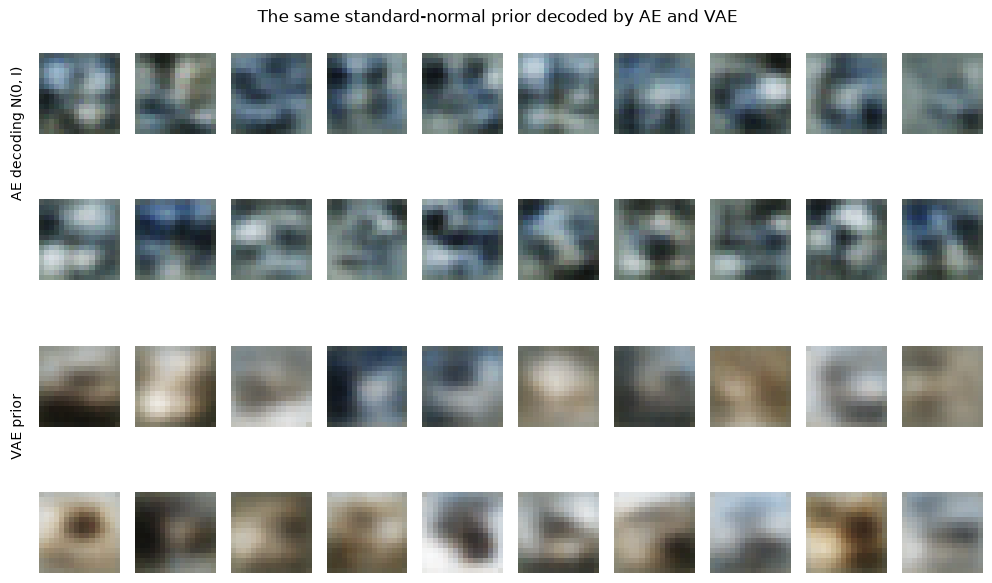

In [14]:
@torch.no_grad()
def sample_decoder(model, number_images, seed=0):
    model.eval()
    local_generator = torch.Generator(device=DEVICE).manual_seed(seed)
    # sample standard-normal codes, decode them, apply sigmoid, and return CPU images.
    codes = torch.randn(number_images, model.latent_dim, generator=local_generator, device=DEVICE)
    decoded_images = model.decode(codes)
    return torch.sigmoid(decoded_images).cpu()


ae_samples = sample_decoder(autoencoder_32, 20, seed=SEED + 1)
vae_samples = sample_decoder(vae_32, 20, seed=SEED + 1)
fig, axes = plt.subplots(4, 10, figsize=(10, 6))
for row, (images, label) in enumerate(((ae_samples, "AE decoding N(0, I)"), (vae_samples, "VAE prior"))):
    for offset, image in enumerate(images):
        plot_row = 2 * row + offset // 10
        column = offset % 10
        axes[plot_row, column].imshow(image.permute(1, 2, 0).clamp(0, 1))
        axes[plot_row, column].axis("off")
    axes[2 * row, 0].text(-0.18, 0, label, transform=axes[2 * row, 0].transAxes, rotation=90, va="center", ha="right")
plt.suptitle("The same standard-normal prior decoded by AE and VAE")
plt.tight_layout()
plt.show()

## 11. Compare training curves

AE reconstruction loss and VAE reconstruction loss use the same scale. We plot the wider-model histories because those models drive the later qualitative comparisons. The VAE total is larger because it also contains KL regularization. Avoid interpreting the final total-loss difference as a pure reconstruction-quality comparison.

### Exercise 9 — Plot reconstruction and KL behavior

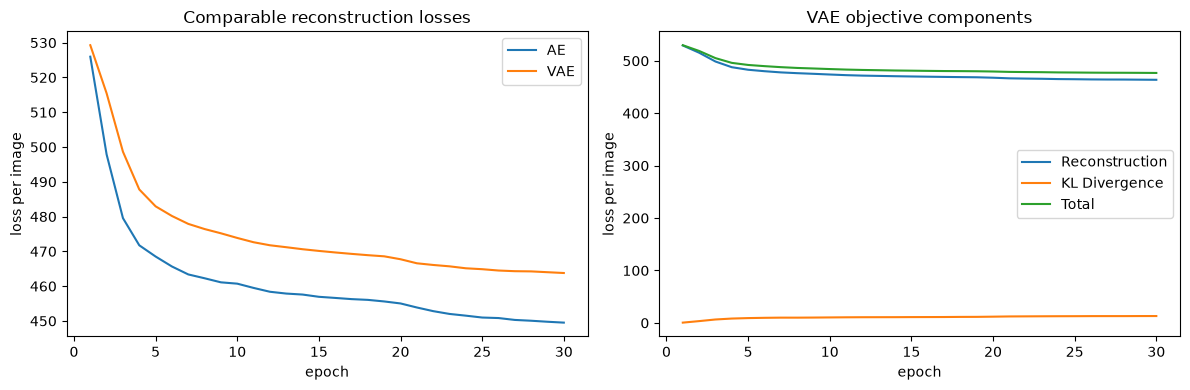

In [15]:
epochs = np.arange(1, len(ae_history_32["reconstruction"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# plot ae_history_32 and vae_history_32 reconstruction values on axes[0].
axes[0].plot(epochs, ae_history_32["reconstruction"], label="AE")
axes[0].plot(epochs, vae_history_32["reconstruction"], label="VAE")
# plot vae_history_32 reconstruction, KL, and total values on axes[1].
axes[1].plot(epochs, vae_history_32["reconstruction"], label="Reconstruction")
axes[1].plot(epochs, vae_history_32["kl"], label="KL Divergence")
axes[1].plot(epochs, vae_history_32["total"], label="Total")
axes[0].set(title="Comparable reconstruction losses", xlabel="epoch", ylabel="loss per image")
axes[1].set(title="VAE objective components", xlabel="epoch", ylabel="loss per image")
for axis in axes:
    axis.legend()
plt.tight_layout()
plt.show()

- AE has the best reconstruction because it only optimizes reconstruction.
- VAE reconstruction is somewhat worse because it also regularizes its latent distribution.
- KL grows from nearly zero to about 13 as the encoder begins using its latent variables.
- Total loss remains reconstruction plus KL.

## 12. Optional beta comparison

The coefficient $\beta$ controls the reconstruction–regularization trade-off:

$$
\mathcal{L}=\mathcal{L}_{reconstruction}+\beta\mathcal{L}_{KL}.
$$

A smaller $\beta$ usually allows better reconstruction but a less prior-compatible latent space. A larger $\beta$ increases prior pressure and can make reconstructions softer; if excessive, it can cause posterior collapse.

The following experiment is disabled by default because training several additional models can take time. Enable it after completing the main comparison.

In [61]:
RUN_BETA_COMPARISON = True
beta_results = {}
if RUN_BETA_COMPARISON:
    for beta in (0.1, 1.0, 4.0):
        torch.manual_seed(SEED)
        beta_model = ConvolutionalVAE(latent_dim=32).to(DEVICE)
        beta_history = train_reconstruction_model(beta_model, train_loader, epochs=10, beta=beta)
        beta_results[beta] = (beta_model, beta_history)

    for beta, (_, beta_history) in beta_results.items():
        print(
            f"beta={beta}: reconstruction={beta_history['reconstruction'][-1]:.2f}, "
            f"KL={beta_history['kl'][-1]:.2f}"
        )

epoch  1: total=527.49, reconstruction=526.84, kl=6.50
epoch  5: total=474.54, reconstruction=470.59, kl=39.45
epoch 10: total=466.37, reconstruction=461.90, kl=44.77
epoch  1: total=529.77, reconstruction=529.28, kl=0.49
epoch  5: total=492.10, reconstruction=482.95, kl=9.15
epoch 10: total=484.27, reconstruction=473.86, kl=10.40
epoch  1: total=530.47, reconstruction=530.37, kl=0.03
epoch  5: total=509.98, reconstruction=499.96, kl=2.51
epoch 10: total=501.79, reconstruction=489.44, kl=3.09
beta=0.1: reconstruction=461.90, KL=44.77
beta=1.0: reconstruction=473.86, KL=10.40
beta=4.0: reconstruction=489.44, KL=3.09


## Reflection

1. Why are CIFAR reconstruction targets kept in $[0,1]$ rather than channel-standardized?
2. Why is a two-dimensional bottleneck useful here even though it limits reconstruction quality?
3. Why do we decode the VAE posterior mean for the deterministic reconstruction comparison?
4. Which model reconstructed more sharply, and why is that result reasonable?
5. Why does class overlap in the latent plot not necessarily mean the models failed?
6. Why is interpolation not the same operation as unconditional generation?
7. Why can standard-normal samples be unreliable for the deterministic AE?
8. What does the VAE KL curve reveal that reconstruction loss alone does not?
9. What trade-off would you expect when increasing $\beta$?
10. What would likely change if the latent width increased from 2 to 32?

### Answers

1. Sigmoid converts decoder logits into values in \([0,1]\), and binary cross-entropy expects targets in that same range. Channel standardization would produce values outside it.
2. A two-dimensional bottleneck can be plotted directly without dimensionality reduction, making latent geometry easy to inspect, although it severely limits reconstruction capacity.
3. The posterior mean is deterministic and represents the center of the image-specific latent distribution. Using it removes random sampling variation and makes reconstructions reproducible.
4. The AE reconstructed more sharply because it optimizes reconstruction alone. The VAE trades some reconstruction quality for KL regularization and a more structured latent space.
5. The models were trained for reconstruction, not classification. Their latent coordinates may represent color, background, pose, and texture rather than separating semantic classes.
6. Interpolation starts from latent representations of two observed images and follows a path between them. Unconditional generation starts from a newly sampled prior code without an input image.
7. The AE was not trained to make its encoded codes match $\mathcal N(0,I)$. Random standard-normal vectors can therefore fall in latent regions its decoder never encountered.
8. The KL curve shows how strongly the approximate posteriors differ from the prior. A value near zero may indicate that the encoder is not using the latent variables, while a growing nonzero value suggests that it is encoding image-specific information while paying a regularization cost.
9. Increasing $\beta$ strengthens prior matching, usually producing a more standard-normal-compatible latent space but worse or softer reconstructions. Excessive $\beta$ can cause posterior collapse.”
10. Increasing the latent width gives the model more capacity and substantially improves reconstruction. It prevents direct two-dimensional visualization and may make prior matching more difficult; generation quality can improve, but it is not guaranteed.